## Code to reproduce plots for the diabetes dataset

To load the data change the working the directory to where the data is located.

In [88]:
import os
import pandas as pd
os.getcwd()
data_path = os.path.join(
    os.getcwd(),
    "diabetic_data.csv",
)
diabetes_data = pd.read_csv(data_path, na_values="?")
diabetes_data.head()


/var/folders/wy/rjc3g8f931scylz5nzw7hrxc0000gn/T/ipykernel_78399/3863067862.py:8: DtypeWarning: Columns (10) have mixed types. Specify dtype option on import or set low_memory=False.
  diabetes_data = pd.read_csv(data_path, na_values="?")


,encounter_id,patient_nbr,race,gender,age,weight,admission_type_id,discharge_disposition_id,admission_source_id,time_in_hospital,...,citoglipton,insulin,glyburide-metformin,glipizide-metformin,glimepiride-pioglitazone,metformin-rosiglitazone,metformin-pioglitazone,change,diabetesMed,readmitted
0,2278392,8222157,Caucasian,Female,[0-10),NaN,6,25,1,1,...,No,No,No,No,No,No,No,No,No,NO
1,149190,55629189,Caucasian,Female,[10-20),NaN,1,1,7,3,...,No,Up,No,No,No,No,No,Ch,Yes,>30
2,64410,86047875,AfricanAmerican,Female,[20-30),NaN,1,1,7,2,...,No,No,No,No,No,No,No,No,Yes,NO
3,500364,82442376,Caucasian,Male,[30-40),NaN,1,1,7,2,...,No,Up,No,No,No,No,No,Ch,Yes,NO
4,16680,42519267,Caucasian,Male,[40-50),NaN,1,1,7,1,...,No,Steady,No,No,No,No,No,Ch,Yes,NO


In [89]:
diabetes_data.info() # there are many missing data for weight, payer_code, medical_specialty and race

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 101766 entries, 0 to 101765
Data columns (total 50 columns):
 #   Column                    Non-Null Count   Dtype 
---  ------                    --------------   ----- 
 0   encounter_id              101766 non-null  int64 
 1   patient_nbr               101766 non-null  int64 
 2   race                      99493 non-null   object
 3   gender                    101766 non-null  object
 4   age                       101766 non-null  object
 5   weight                    3197 non-null    object
 6   admission_type_id         101766 non-null  int64 
 7   discharge_disposition_id  101766 non-null  int64 
 8   admission_source_id       101766 non-null  int64 
 9   time_in_hospital          101766 non-null  int64 
 10  payer_code                61510 non-null   object
 11  medical_specialty         51817 non-null   object
 12  num_lab_procedures        101766 non-null  int64 
 13  num_procedures            101766 non-null  int64 
 14  num_

1. Age group distribution visualized as barchart

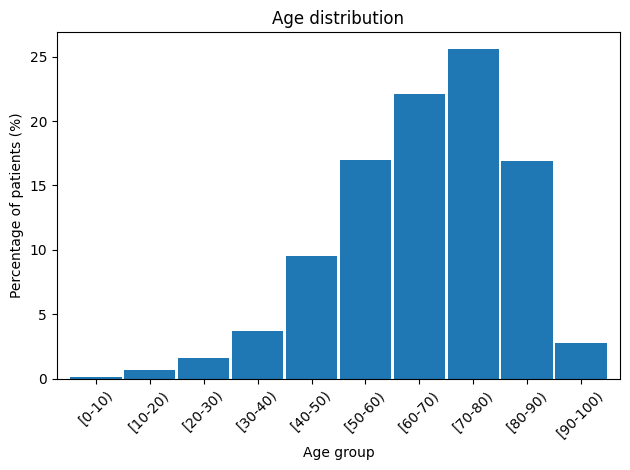

In [90]:
import matplotlib.pyplot as plt
age_percent = diabetes_data["age"].value_counts(normalize=True).sort_index() * 100

age_percent.plot(kind="bar", width=0.95)
plt.xlabel("Age group")
plt.ylabel("Percentage of patients (%)")
plt.title("Age distribution")
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig("age_distribution.png", dpi=300, bbox_inches="tight")
plt.show()

2. Length of stay in hospital visualized as a density function

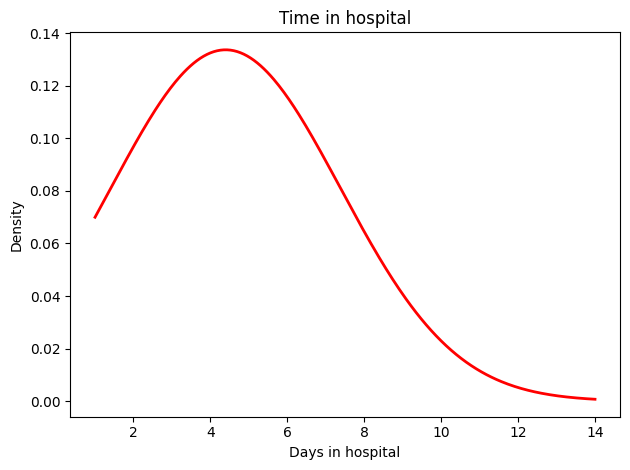

In [91]:
import numpy as np
from scipy.stats import norm

x = diabetes_data["time_in_hospital"].dropna()
x_curve = np.linspace(x.min(), x.max(), 300)

plt.plot(
    x_curve,
    norm.pdf(x_curve, x.mean(), x.std()),
    color="red",
    linewidth=2,
)

plt.xlabel("Days in hospital")
plt.ylabel("Density")
plt.title("Time in hospital")
plt.tight_layout()
plt.savefig("time_in_hospital.png", dpi=300, bbox_inches="tight")
plt.show()

3. Readmission distribution

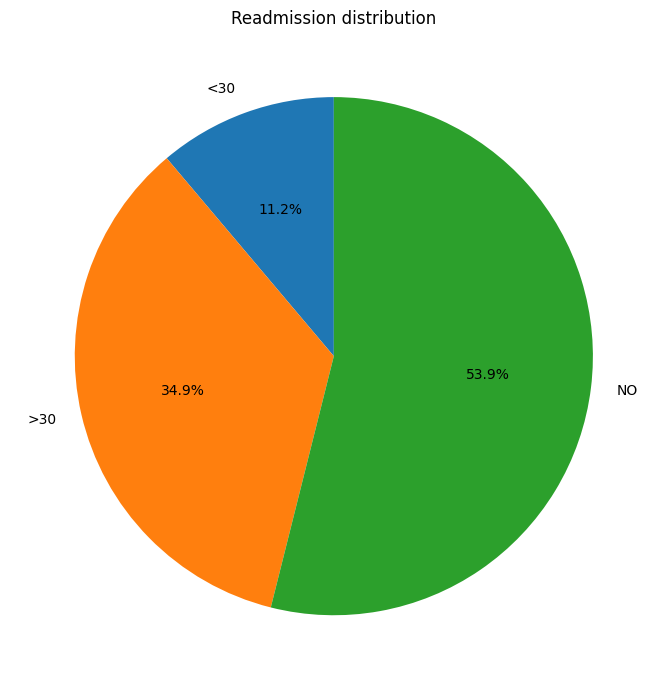

In [92]:
readmission_percent = diabetes_data["readmitted"].value_counts(normalize=True).sort_index() * 100

plt.figure(figsize=(7, 7))
plt.pie(
    readmission_percent,
    labels=readmission_percent.index,
    autopct="%1.1f%%",
    startangle=90,
)
plt.title("Readmission distribution")
plt.tight_layout()
plt.savefig("readmissions_chart.png", dpi=300, bbox_inches="tight")
plt.show()

In order to have balanced classes we consider from now on the target variable 'readmission' as binary with outcome Yes/No and define it as 'readmission_2'.

In [93]:
diabetes_data["readmission_2"] = (
    diabetes_data["readmitted"].isin(["<30", ">30"]).astype(int)
)
diabetes_data["readmission_2"].value_counts(normalize=True) * 100

readmission_2
0    53.911916
1    46.088084
Name: proportion, dtype: float64

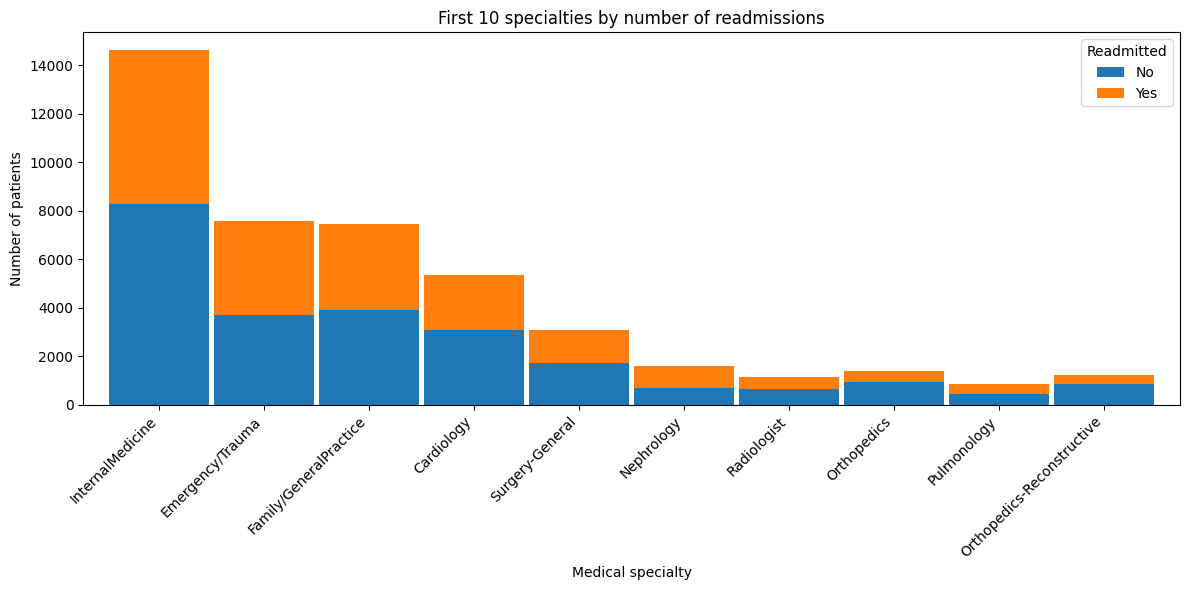

In [94]:
specialty_counts = pd.crosstab(
    diabetes_data["medical_specialty"],
    diabetes_data["readmission_2"],
)

top_10 = specialty_counts.sort_values(by=1, ascending=False).head(10)

top_10.plot(kind="bar", stacked=True, figsize=(12, 6), width=0.95)

plt.xlabel("Medical specialty")
plt.ylabel("Number of patients")
plt.title("First 10 specialties by number of readmissions")
plt.legend(title="Readmitted", labels=["No", "Yes"])
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

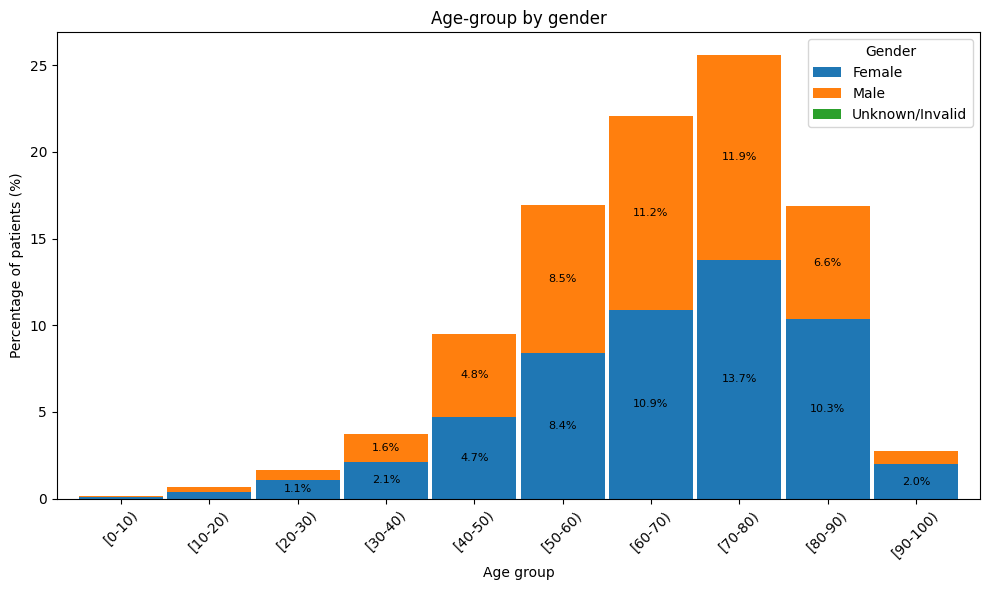

In [95]:
age_gender_percent = pd.crosstab(
    diabetes_data["age"],
    diabetes_data["gender"],
    normalize=True,
) * 100

ax = age_gender_percent.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6),
    width=0.95,
)

for container in ax.containers:
    labels = [
        f"{bar.get_height():.1f}%" if bar.get_height() >= 1 else ""
        for bar in container
    ]
    ax.bar_label(container, labels=labels, label_type="center", fontsize=8)

plt.xlabel("Age group")
plt.ylabel("Percentage of patients (%)")
plt.title("Age-group by gender")
plt.legend(title="Gender")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [96]:
diabetes_data["payer_code"].value_counts(dropna=False) # too many missing values

payer_code
NaN    40256
MC     32439
HM      6274
SP      5007
BC      4655
MD      3532
CP      2533
UN      2448
CM      1937
OG      1033
PO       592
DM       549
CH       146
WC       135
OT        95
MP        79
SI        55
FR         1
Name: count, dtype: int64

Diagnostic codes were grouped using the MSP ICD-9 index [[1]](#ref1).

In [97]:
import pandas as pd

def icd9_category(code):
    if pd.isna(code):
        return "Missing"

    code = str(code).strip().upper()

    if code.startswith("V"):
        return "Supplementary factors (V codes)"
    if code.startswith("E"):
        return "External causes (E codes)"

    try:
        number = int(float(code))
    except ValueError:
        return "Unknown"

    ranges = [
        (1, 139, "Infectious and parasitic diseases"),
        (140, 239, "Neoplasms"),
        (240, 279, "Endocrine, nutritional, and metabolic diseases"),
        (280, 289, "Blood diseases"),
        (290, 319, "Mental disorders"),
        (320, 389, "Nervous system and sense organs"),
        (390, 459, "Circulatory system"),
        (460, 519, "Respiratory system"),
        (520, 579, "Digestive system"),
        (580, 629, "Genitourinary system"),
        (630, 679, "Pregnancy and childbirth"),
        (680, 709, "Skin and subcutaneous tissue"),
        (710, 739, "Musculoskeletal system"),
        (740, 759, "Congenital anomalies"),
        (760, 779, "Perinatal conditions"),
        (780, 799, "Symptoms and ill-defined conditions"),
        (800, 999, "Injury and poisoning"),
    ]

    for low, high, label in ranges:
        if low <= number <= high:
            return label

    return "Other or unclassified"

diabetes_data["diag_1_category"] = diabetes_data["diag_1"].apply(icd9_category)
diabetes_data["diag_2_category"] = diabetes_data["diag_2"].apply(icd9_category)
diabetes_data["diag_3_category"] = diabetes_data["diag_3"].apply(icd9_category)

4. Primary diagnosis and Readmission

In [98]:
def plot_diagnosis_readmissions(category_col, diagnosis_label):
    counts = pd.crosstab(
        diabetes_data[category_col],
        diabetes_data["readmission_2"],
    )

    # Keep categories with at least one readmission, sorted by readmission count
    counts = counts[counts[1] > 0].sort_values(by=1, ascending=False)

    ax = counts.plot(
        kind="bar",
        stacked=True,
        figsize=(12, 6),
        width=0.95,
    )

    for container in ax.containers:
        labels = []
        for bar in container:
            category_total = counts.iloc[int(bar.get_x() + bar.get_width() / 2) if False else 0].sum()
            labels.append(f"{bar.get_height() / category_total:.1%}" if bar.get_height() > 0 else "")
        ax.bar_label(container, labels=labels, label_type="center", fontsize=8)

    ax.set_xlabel(diagnosis_label)
    ax.set_ylabel("Number of patients")
    ax.set_title(f"{diagnosis_label} and readmission")
    ax.legend(title="Readmitted", labels=["No", "Yes"])
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.savefig("diagnosis_readmissions.png", dpi=300, bbox_inches="tight")
    plt.show()

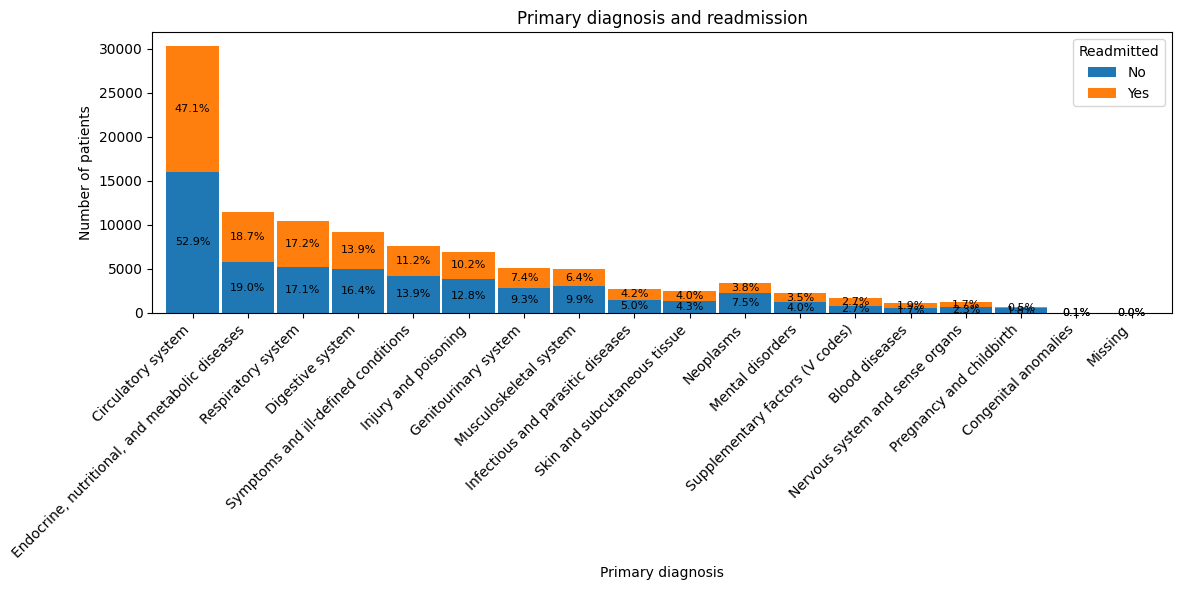

In [99]:

plot_diagnosis_readmissions("diag_1_category", "Primary diagnosis")

## References
<a id="ref1"></a>[1] British Columbia Ministry of Health, *Index for 3 and 4 Digit Diagnostic Codes (ICD9)*, Medical Services Plan, Government of British Columbia, n.d. [Online]. Available: https://www2.gov.bc.ca/assets/gov/health/practitioner-pro/medical-services-plan/diag-codes-index.pdf (accessed Oct. 22, 2026).